# Task 5 — Time-Series Preprocessing & Forecasting
**Data:** daily weather for Alexandria, Egypt, 2021–2025 (the cleaned dataset from Task 4, NASA POWER)  |  **Target:** daily mean temperature (°C)

The task handout is written for **hourly** data, where the seasonal period is m = 24. Our data is **daily**, and its strong cycle is **yearly**, so the seasonal period would be m ≈ 365. A classic SARIMAX(seasonal_order=(P,D,Q,365))` is not practical (the state vector grows with m, so it is extremely slow and memory-hungry). The standard professional fix is **dynamic harmonic regression**: model the yearly cycle with a few sine/cosine (Fourier) terms passed as exogenous regressors, and let the ARIMA part model the leftover day-to-day dynamics. We call this model **SARIMA-F** (SARIMAX with Fourier seasonality). It does exactly the job of the seasonal part of SARIMA.

In [1]:

import warnings, time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 100
SEED = 42; np.random.seed(SEED); random.seed(SEED)

# ---------- configuration ----------
DATA_PATH = "alexandria_weather_clean.csv"
TARGET    = "temperature"                    # daily mean temperature in degrees C
H         = 30                               # forecast horizon = test size = 30 days (about 4 weeks)
FIG_DIR   = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
def savefig(name): plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

# 1. Recap: where Task 4 left off
In Task 4 we pulled 1,826 daily records for Alexandria from NASA POWER (1 Jan 2021 → 31 Dec 2025) and found:
* a **very strong yearly cycle** in temperature (seasonal strength 0.93, swing ≈ 21 °C),
* essentially no trend (the 5-year record is too short),
* no gaps, duplicates or missing values, and a couple of rolling-z-score outliers.

> **TIP** everything downstream (resampling, ARIMA, LSTM windowing) depends on the index being a proper DatetimeIndex **with a defined frequency**. A CSV does not store the frequency, so we must set it ourselves.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"], index_col="date")
print("Index type     :", type(df.index).__name__)
print("Frequency (raw):", df.index.freq, " <- None after reading a CSV, we fix this next")
print("Range          :", df.index.min().date(), "->", df.index.max().date(), "| rows:", len(df))
df.head(3)

Index type     : DatetimeIndex
Frequency (raw): None  <- None after reading a CSV, we fix this next
Range          : 2021-01-01 -> 2025-12-31 | rows: 1826


,temperature,temp_max,temp_min,precipitation,humidity,wind_speed,cloud_cover
date,,,,,,,
2021-01-01,16.61,21.28,13.44,0.0,71.51,2.41,34.00
2021-01-02,17.10,21.77,13.56,0.0,76.06,2.57,62.54
2021-01-03,17.25,22.67,13.85,0.0,81.02,2.51,21.14


# 2. Preprocessing for time series

## Resampling and frequency alignment
asfreq("D") forces a regular daily grid. If any date were missing, it would insert a row of NaN, which makes gaps visible instead of silently hiding them. This matters because ARIMA, differencing (diff(k)) and LSTM windows all assume that **one row = one day**.

In [3]:
df = df.asfreq("D")
print("Frequency after asfreq:", df.index.freq)
print("Rows:", len(df), "| expected:", (df.index.max() - df.index.min()).days + 1)
print("\nGaps introduced by resampling (NaN count per column):")
print(df.isna().sum().to_string())
y_raw = df[TARGET].copy()

Frequency after asfreq: <Day>
Rows: 1826 | expected: 1826

Gaps introduced by resampling (NaN count per column):
temperature      0
temp_max         0
temp_min         0
precipitation    0
humidity         0
wind_speed       0
cloud_cover      0


##Handling missing values
Weather variables are smooth and autocorrelated, so we never use the mean/median to fill (that would drop the seasonal shape). Strategy, following the handout:

| Gap length | Method | Why |
|---|---|---|
| **short (≤ 3 days)** | time interpolation | neighbouring days are nearly identical |
| **longer** | **seasonal-naive fill**: value from the same day one year earlier (or later) | keeps the seasonal shape that a straight line would destroy |
| any | **never forward-fill** long stretches | it produces a flat line that destroys the signal |

Our data has no gaps, so to show the function really works we test it on **artificial gaps** where we know the true answer.

In [4]:
def fill_missing(s, max_gap=3, season=365):
    # Short gaps -> time interpolation. Long gaps -> seasonal-naive (same day last/next year).
    s = s.copy(); isna = s.isna()
    if not isna.any():
        return s, {"short_filled": 0, "long_filled": 0}
    run_id  = (isna != isna.shift()).cumsum()
    run_len = isna.groupby(run_id).transform("sum")          # length of the NaN run each NaN belongs to
    short, long_ = isna & (run_len <= max_gap), isna & (run_len > max_gap)
    interp  = s.interpolate(method="time", limit_direction="both")
    s[short] = interp[short]
    seasonal = s.shift(season).fillna(s.shift(-season))      # same day previous year, else next year
    s[long_] = seasonal[long_]
    s = s.interpolate(method="time", limit_direction="both") # safety net
    return s, {"short_filled": int(short.sum()), "long_filled": int(long_.sum())}

# ---- demo on artificial gaps: a 2-day gap and a 15-day gap in the middle of the record
demo = y_raw.copy(); truth = y_raw.copy()
short_idx = demo.index[600:602]; long_idx = demo.index[900:915]
demo[short_idx] = np.nan; demo[long_idx] = np.nan
filled, info = fill_missing(demo)
ffill = demo.ffill()
lin   = demo.interpolate(method="time")
mae = lambda a, b: float(np.mean(np.abs(a - b)))
print(info)
print(f"15-day gap, MAE vs truth -> seasonal-naive fill: {mae(filled[long_idx], truth[long_idx]):.2f} C | "
      f"linear interpolation: {mae(lin[long_idx], truth[long_idx]):.2f} C | forward-fill: {mae(ffill[long_idx], truth[long_idx]):.2f} C")
print(f" 2-day gap, MAE vs truth -> time interpolation: {mae(filled[short_idx], truth[short_idx]):.2f} C")

{'short_filled': 2, 'long_filled': 15}
15-day gap, MAE vs truth -> seasonal-naive fill: 0.71 C | linear interpolation: 1.60 C | forward-fill: 2.51 C
 2-day gap, MAE vs truth -> time interpolation: 0.65 C


**Reading the demo:** for the short gap, interpolation is accurate. For the long gap, compare the three errors above: this is the evidence behind the handout's rule *"never forward-fill long stretches of a continuous variable"*. Now we apply the same function to the real series (it will report 0 filled values, because Task 4 already left a gap-free series).

In [5]:
y, fill_info = fill_missing(y_raw)
print("Filled on the real series:", fill_info, "| remaining NaN:", int(y.isna().sum()))

Filled on the real series: {'short_filled': 0, 'long_filled': 0} | remaining NaN: 0


##Outlier treatment


Physically impossible values: 0
Rolling z-score outliers (|z| > 3): 2
Days changed by capping: 2
            original  capped  z-score
date                                 
2024-01-31     10.54   10.69    -3.10
2024-03-01     19.69   19.62     3.06


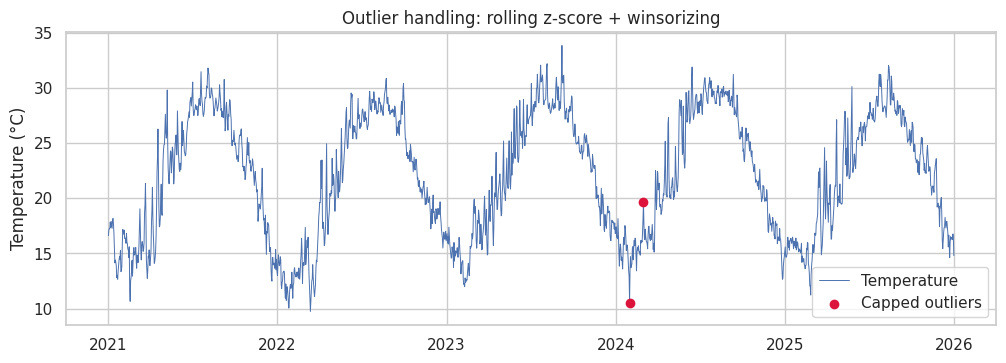

In [6]:
LOW, HIGH = -5, 50                                   # plausible range for Alexandria, degrees C
print("Physically impossible values:", int(((y < LOW) | (y > HIGH)).sum()))

W = 31
roll_mean = y.rolling(W, center=True, min_periods=10).mean()
roll_std  = y.rolling(W, center=True, min_periods=10).std()
z = (y - roll_mean) / roll_std
flagged = z.abs() > 3
print("Rolling z-score outliers (|z| > 3):", int(flagged.sum()))

# winsorize: cap each value to its local mean +/- 3 std (only flagged days change)
y_clean = y.clip(lower=roll_mean - 3 * roll_std, upper=roll_mean + 3 * roll_std)
changed = (y_clean - y).abs() > 1e-9
print("Days changed by capping:", int(changed.sum()))
print(pd.DataFrame({"original": y[changed], "capped": y_clean[changed].round(2), "z-score": z[changed].round(2)}))

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(y.index, y, lw=.7, label="Temperature")
ax.scatter(y[changed].index, y[changed], color="crimson", zorder=3, label="Capped outliers")
ax.set_title("Outlier handling: rolling z-score + winsorizing"); ax.set_ylabel("Temperature (°C)"); ax.legend()
savefig("01_outliers.png"); plt.show()
y = y_clean.copy(); y.name = TARGET

##Feature engineering
| Feature type | Columns | Used by |
|---|---|---|
| **Calendar** | day of week, month, day of year, is_weekend | ML / LSTM (weekday is almost meaningless for weather, we test that below) |
| **Cyclical encoding** | `sin/cos` of day-of-year and month | LSTM (and, in spirit, the Fourier terms in SARIMA-F). Makes 31 Dec "next to" 1 Jan |
| **Lags** | t-1, t-7, t-365 | ML / baselines (t-365 = seasonal-naive baseline) |
| **Rolling statistics** | rolling mean/std over 7 and 30 days | local trend and volatility |

In [7]:
feat = pd.DataFrame({TARGET: y})
idx = feat.index
feat["dayofyear"]  = idx.dayofyear
feat["month"]      = idx.month
feat["dayofweek"]  = idx.dayofweek
feat["is_weekend"] = (idx.dayofweek >= 5).astype(int)
feat["doy_sin"]    = np.sin(2 * np.pi * idx.dayofyear / 365.25)
feat["doy_cos"]    = np.cos(2 * np.pi * idx.dayofyear / 365.25)
feat["month_sin"]  = np.sin(2 * np.pi * idx.month / 12)
feat["month_cos"]  = np.cos(2 * np.pi * idx.month / 12)
for lag in (1, 7, 365):
    feat[f"lag_{lag}"] = y.shift(lag)
for w in (7, 30):                                   # shift(1) -> no leakage
    feat[f"roll_mean_{w}"] = y.shift(1).rolling(w).mean()
    feat[f"roll_std_{w}"]  = y.shift(1).rolling(w).std()

corr = feat.drop(columns=[TARGET]).corrwith(feat[TARGET]).sort_values(key=np.abs, ascending=False)
print(corr.round(3).to_string())
display(feat.dropna().head(3).round(2))

lag_1           0.979
roll_mean_7     0.957
roll_mean_30    0.920
lag_7           0.915
lag_365         0.908
doy_cos        -0.789
month_sin      -0.708
month_cos      -0.618
doy_sin        -0.530
month           0.417
dayofyear       0.413
roll_std_30    -0.078
roll_std_7     -0.063
dayofweek       0.005
is_weekend      0.003


,temperature,dayofyear,month,dayofweek,is_weekend,doy_sin,doy_cos,month_sin,month_cos,lag_1,lag_7,lag_365,roll_mean_7,roll_std_7,roll_mean_30,roll_std_30
date,,,,,,,,,,,,,,,,
2022-01-01,12.99,1,1,5,1,0.02,1.0,0.5,0.87,13.34,14.12,16.61,14.10,0.69,15.48,1.76
2022-01-02,14.08,2,1,6,1,0.03,1.0,0.5,0.87,12.99,13.66,17.10,13.94,0.81,15.31,1.75
2022-01-03,14.87,3,1,0,0,0.05,1.0,0.5,0.87,14.08,14.26,17.25,14.00,0.80,15.18,1.68


**What the correlations tell us:** lag_1, the rolling means and the cyclical day-of-year terms are strongly related to temperature, while is_weekend / dayofweek are about zero: **there is no weekly cycle in weather**, so a weekly seasonal period (`m = 7`) would be wrong. Classic ARIMA does not use these columns directly; it learns the same information from its own lags and from the Fourier terms. They are mainly for the LSTM in Section 6.

## Train / test split
> **Critical rule:** never shuffle a time series. We use a chronological cut: the **last 30 days (4 weeks) are the test set**, and the model sees nothing from that period. Shuffling would let the model "peek" at neighbouring days and inflate accuracy.

Note:`df.loc[:split_date], df.loc[split_date:]` includes `split_date` in *both* sets. We cut exactly, so the sets do not overlap.

Train: 2021-01-01 -> 2025-12-01  (1796 days)
Test : 2025-12-02 -> 2025-12-31  (30 days)


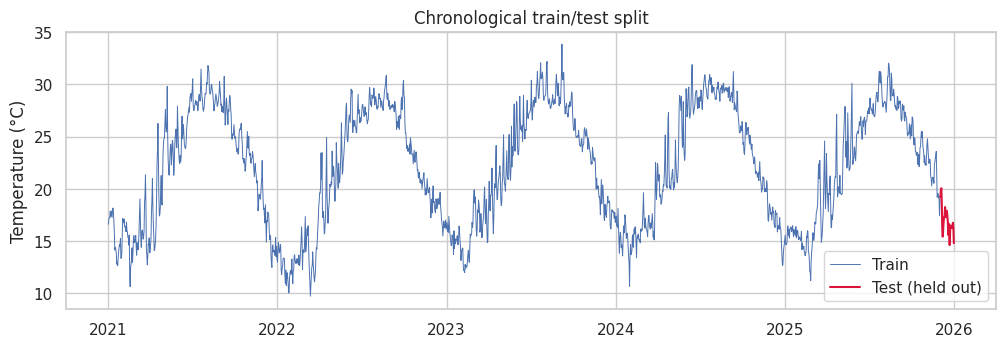

In [8]:
split_date = y.index[-H]                              # first day of the test set
train = y.loc[: split_date - pd.Timedelta(days=1)]
test  = y.loc[split_date:]
print(f"Train: {train.index[0].date()} -> {train.index[-1].date()}  ({len(train)} days)")
print(f"Test : {test.index[0].date()} -> {test.index[-1].date()}  ({len(test)} days)")
assert train.index.max() < test.index.min() and len(set(train.index) & set(test.index)) == 0

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(train.index, train, lw=.7, label="Train"); ax.plot(test.index, test, lw=1.5, color="crimson", label="Test (held out)")
ax.set_title("Chronological train/test split"); ax.set_ylabel("Temperature (°C)"); ax.legend()
savefig("02_split.png"); plt.show()

##Scaling
* **ARIMA/SARIMA:** no scaling, they model the raw (or differenced) series.
* **RNN/LSTM:** `MinMaxScaler` **fitted on the training split only**, then applied to the test split (done in Section 6).

In [9]:
model_ready = feat.copy()
model_ready["split"] = np.where(model_ready.index < split_date, "train", "test")
model_ready.to_csv("alexandria_temperature_model_ready.csv", index_label="date")
print("Saved alexandria_temperature_model_ready.csv", model_ready.shape)
print("Index frequency:", y.index.freq, "| NaN in target:", int(y.isna().sum()))

Saved alexandria_temperature_model_ready.csv (1826, 17)
Index frequency: <Day> | NaN in target: 0


# 3. Stationarity checks
ARIMA needs (after differencing) a series with constant mean/variance/autocorrelation. Two tests with **opposite** null hypotheses:

| Test | H₀ | p < 0.05 means |
|---|---|---|
| **ADF** | has a unit root (non-stationary) | stationary |
| **KPSS** | is stationary | non-stationary |


## Modelling the yearly cycle with Fourier terms
A pair `sin(2πkt/365.25), cos(2πkt/365.25)` is one "harmonic". More harmonics capture a more complicated seasonal shape. We choose **K** (number of harmonics) with **AIC**, using a simple AR(1) error model. This comparison is valid because all candidates use the same differencing.

In [10]:
T0 = y.index[0]
def fourier(idx, K, t0=T0, period=365.25):
    # Deterministic Fourier terms (they only depend on the calendar, so we can compute them for future dates too).
    if K == 0: return None
    t = np.asarray((idx - t0).days, dtype=float); cols = {}
    for k in range(1, K + 1):
        cols[f"sin{k}"] = np.sin(2 * np.pi * k * t / period); cols[f"cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(cols, index=idx)

rows = []
for K in range(1, 6):
    r = SARIMAX(train, exog=fourier(train.index, K), order=(1, 0, 0)).fit(disp=False)
    rows.append({"K": K, "AIC": round(r.aic, 1), "BIC": round(r.bic, 1)})
kdf = pd.DataFrame(rows); display(kdf)
K_BEST = int(kdf.loc[kdf["AIC"].idxmin(), "K"])
print("Chosen number of harmonics K =", K_BEST)

,K,AIC,BIC
0,1,5579.5,5601.5
1,2,5583.4,5616.4
2,3,5587.4,5631.4
3,4,5591.4,5646.3
4,5,5595.3,5661.3


Chosen number of harmonics K = 1


##ADF and KPSS on the raw, differenced and deseasonalised series

In [11]:
def stat_test(s, name):
    s = s.dropna()
    adf_p  = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    adf_v  = "stationary" if adf_p < 0.05 else "NON-stationary"
    kpss_v = "stationary" if kpss_p >= 0.05 else "NON-stationary"
    both = "agree: stationary" if (adf_v == "stationary" and kpss_v == "stationary") else (
           "agree: NON-stationary" if (adf_v != "stationary" and kpss_v != "stationary") else "DISAGREE")
    return {"series": name, "ADF p": round(adf_p, 4), "ADF says": adf_v, "KPSS p (capped 0.01-0.10)": round(kpss_p, 3), "KPSS says": kpss_v, "verdict": both}

# remove the yearly cycle by regressing on Fourier terms (training data only)
ols = sm.OLS(train, sm.add_constant(fourier(train.index, K_BEST))).fit()
deseason = ols.resid
print(f"Fourier terms explain {ols.rsquared:.1%} of the variance of daily temperature.")

tests = pd.DataFrame([
    stat_test(train,                 "Raw temperature"),
    stat_test(train.diff(1),         "Raw, first difference d=1"),
    stat_test(train.diff(365),       "Raw, seasonal difference D=1 (lag 365)"),
    stat_test(deseason,              "Deseasonalised (Fourier residual), d=0"),
    stat_test(deseason.diff(1),      "Deseasonalised, first difference d=1"),
])
tests

Fourier terms explain 90.2% of the variance of daily temperature.


,series,ADF p,ADF says,KPSS p (capped 0.01-0.10),KPSS says,verdict
0,Raw temperature,0.2581,NON-stationary,0.100,stationary,DISAGREE
1,"Raw, first difference d=1",0.0000,stationary,0.100,stationary,agree: stationary
2,"Raw, seasonal difference D=1 (lag 365)",0.0000,stationary,0.045,NON-stationary,DISAGREE
3,"Deseasonalised (Fourier residual), d=0",0.0000,stationary,0.010,NON-stationary,DISAGREE
4,"Deseasonalised, first difference d=1",0.0000,stationary,0.100,stationary,agree: stationary


##Differencing decision
How to read the table:
* **Raw temperature:** ADF cannot reject a unit root and the series visibly cycles the mean is **not constant** (the season moves it). It needs the seasonal part handled.
* **After removing the yearly cycle** (deseasonalised): ADF says stationary (no unit root), but **KPSS still rejects** stationarity, which means there is a **slow drift in the level** (this matches the Task 4 finding).
* **First difference of the deseasonalised series:** both tests agree on stationary.

**Decision:** seasonal part, Fourier terms (equivalent to `D=1` but feasible); regular differencing **`d = 0` is what ACF/PACF suggest, `d = 1` is what KPSS suggests**. Because the evidence is split, we do *not* guess: we let a time-aware validation on the **training data only** decide. Differencing more than needed adds noise, so we only keep `d = 1` if it forecasts better.

# 4. ARIMA / SARIMA modelling

##Choosing orders with ACF / PACF
Rules of thumb: **PACF cuts off after lag p → AR(p)**; **ACF cuts off after lag q → MA(q)**; slow decay in one of them points to the other. A spike at the seasonal lag is your seasonal signal. We look at three versions of the series: the raw series (to see the seasonal signal), the deseasonalised series (`d=0`) and its first difference (`d=1`).

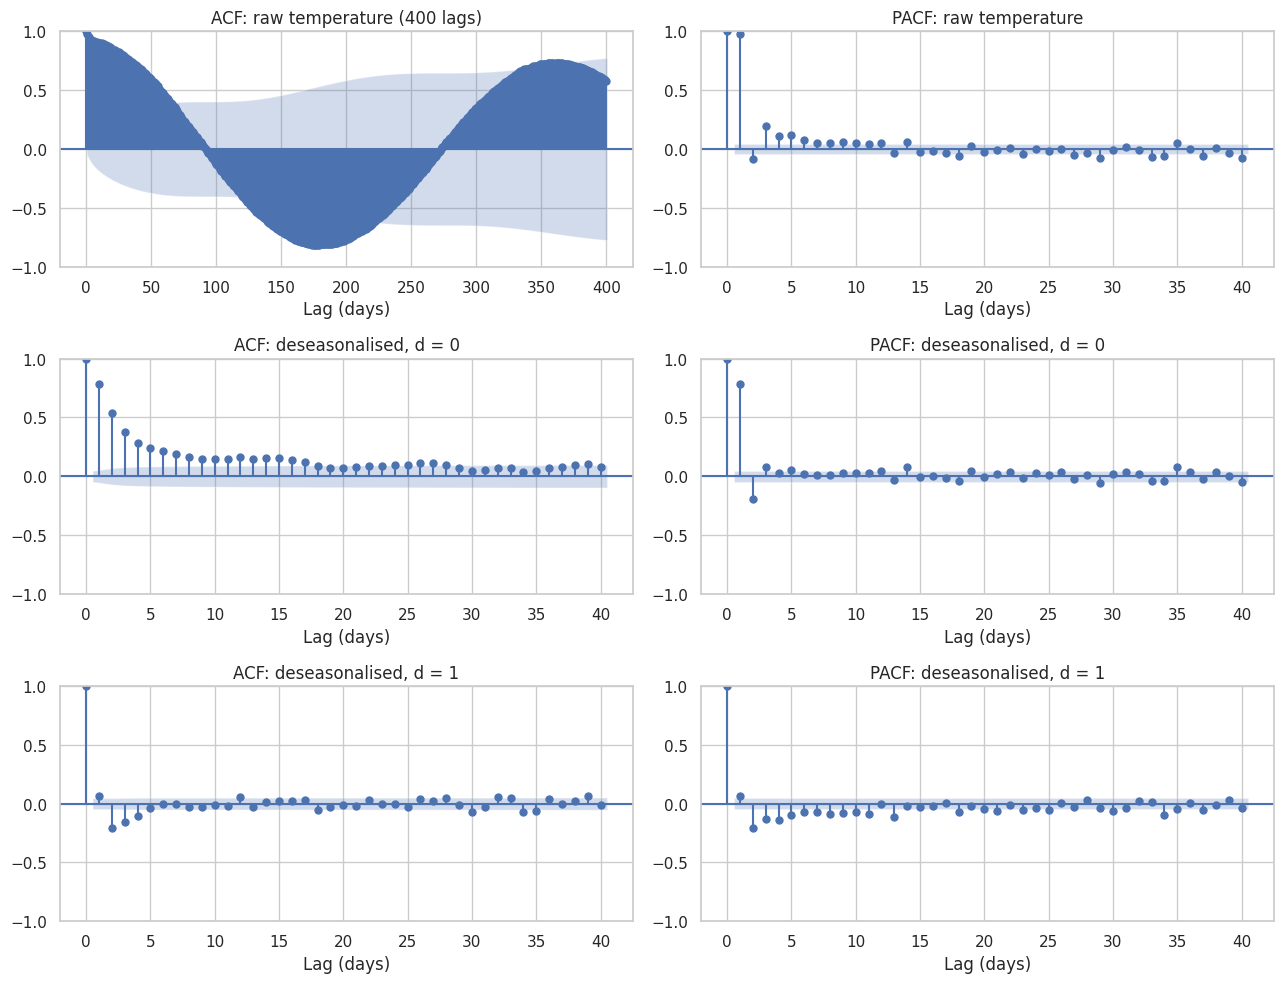

[d=0] significant ACF lags : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
[d=0] significant PACF lags: [1, 2, 3, 5]   (95% band = +/-0.046)
        ACF  lags 1-5 : [0.78 0.54 0.38 0.29 0.24]
        PACF lags 1-5 : [ 0.78 -0.2   0.08  0.03  0.05]
[d=1] significant ACF lags : [1, 2, 3, 4]
[d=1] significant PACF lags: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]   (95% band = +/-0.046)
        ACF  lags 1-5 : [ 0.07 -0.2  -0.16 -0.11 -0.04]
        PACF lags 1-5 : [ 0.07 -0.21 -0.13 -0.14 -0.1 ]

Raw ACF: lag 1 = 0.98, lag 7 = 0.91, lag 182 = -0.81 (negative: opposite season), lag 365 = 0.73 (peak: yearly cycle)


In [12]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
plot_acf(train, lags=400, ax=axes[0, 0]);  axes[0, 0].set_title("ACF: raw temperature (400 lags)")
plot_pacf(train, lags=40, ax=axes[0, 1], method="ywm"); axes[0, 1].set_title("PACF: raw temperature")
plot_acf(deseason, lags=40, ax=axes[1, 0]);  axes[1, 0].set_title("ACF: deseasonalised, d = 0")
plot_pacf(deseason, lags=40, ax=axes[1, 1], method="ywm"); axes[1, 1].set_title("PACF: deseasonalised, d = 0")
d1 = deseason.diff(1).dropna()
plot_acf(d1, lags=40, ax=axes[2, 0]);  axes[2, 0].set_title("ACF: deseasonalised, d = 1")
plot_pacf(d1, lags=40, ax=axes[2, 1], method="ywm"); axes[2, 1].set_title("PACF: deseasonalised, d = 1")
for a in axes.ravel(): a.set_xlabel("Lag (days)")
plt.tight_layout(); savefig("04_acf_pacf.png"); plt.show()

band = 1.96 / np.sqrt(len(deseason))
for name, s in [("d=0", deseason), ("d=1", d1)]:
    a, p = acf(s, nlags=10)[1:], pacf(s, nlags=10)[1:]
    print(f"[{name}] significant ACF lags : {[i+1 for i,v in enumerate(a) if abs(v) > band]}")
    print(f"[{name}] significant PACF lags: {[i+1 for i,v in enumerate(p) if abs(v) > band]}   (95% band = +/-{band:.3f})")
    print(f"        ACF  lags 1-5 : {np.round(a[:5], 2)}")
    print(f"        PACF lags 1-5 : {np.round(p[:5], 2)}")
a_raw = acf(train, nlags=400)
print(f"\nRaw ACF: lag 1 = {a_raw[1]:.2f}, lag 7 = {a_raw[7]:.2f}, lag 182 = {a_raw[182]:.2f} (negative: opposite season), lag 365 = {a_raw[365]:.2f} (peak: yearly cycle)")

### Manual order proposal (reasoned from the plots)
* **Seasonal signal:** the raw ACF swings between positive and negative with a peak near lag 365 → **yearly period**. There is **no spike at lag 7** in the differenced series, so there is no weekly cycle. The textbook seasonal term would be `D=1, m=365`; we implement it with Fourier terms, so formally **(P, D, Q, m) = (0, 0, 0, 0) + K Fourier terms**.
* **Deseasonalised, d = 0:** the **ACF tails off slowly** and the **PACF has a strong spike at lag 1 (≈ 0.78), a smaller one at lag 2 (≈ -0.20), then drops to near zero** → an **AR(2)** process → manual proposal **(p, d, q) = (2, 0, 0)**.
* **Deseasonalised, d = 1:** the ACF and PACF show several small negative spikes (lags 2-4) that tail off, a typical sign of an **MA component**, so a mixed model such as **(2, 1, 1)** is a plausible alternative if the level drifts.


## Automated order search and model selection
We build a pool of candidates: **(a) the manual proposal, (b) `pmdarima.auto_arima`**, **(c) our own AIC grid search** for `d=0` and `d=1`. Warning: AIC values are only comparable between models with the **same** `d`, so the final choice among candidates is made by **walk-forward validation on the training data only** (the test set is never touched during model selection).

In [13]:
Xtr = fourier(train.index, K_BEST)

# ---- (b) pmdarima auto_arima (optional) --------------------------------
auto_order = None
try:
    import pmdarima as pm
    auto_model = pm.auto_arima(train, X=Xtr, seasonal=False, stepwise=True, trace=False, suppress_warnings=True,
                               error_action="ignore", information_criterion="aic", max_p=4, max_q=4, max_d=2)
    auto_order = auto_model.order
    print("pmdarima auto_arima order (p,d,q):", auto_order)
    print(auto_model.summary().tables[0])
except Exception as e:
    print("pmdarima not available, using our own AIC grid only ->", type(e).__name__)

# ---- (c) AIC grid, separately for d = 0 and d = 1 -----------------------
grid_rows = []
for d in (0, 1):
    for p in range(0, 4):
        for q in range(0, 3):
            if p == 0 and q == 0 and d == 0: continue
            try:
                r = SARIMAX(train, exog=Xtr, order=(p, d, q)).fit(disp=False, maxiter=200)
                grid_rows.append({"order": (p, d, q), "d": d, "AIC": r.aic, "BIC": r.bic})
            except Exception:
                pass
grid = pd.DataFrame(grid_rows)
best_by_d = grid.loc[grid.groupby("d")["AIC"].idxmin()]
print("\nBest AIC per differencing level (compare ONLY within the same d):")
display(best_by_d.round(1))

pmdarima not available, using our own AIC grid only -> ModuleNotFoundError

Best AIC per differencing level (compare ONLY within the same d):


,order,d,AIC,BIC
7,"(2, 0, 2)",0,5286.6,5325.1
16,"(1, 1, 2)",1,5275.6,5308.5


In [14]:
# ---------------- helpers used for all statistical models -------------------
def fit_sarimax(ytr, order, K, **kw):
    return SARIMAX(ytr, exog=fourier(ytr.index, K), order=order, **kw).fit(disp=False, maxiter=200)

def forecast_sarimax(res, future_idx, K, alpha=0.05):
    fc = res.get_forecast(steps=len(future_idx), exog=fourier(future_idx, K))
    mean, ci = fc.predicted_mean, fc.conf_int(alpha=alpha)
    mean.index = future_idx; ci.index = future_idx
    return mean, ci

def metrics(actual, pred):
    a, p = np.asarray(actual, float), np.asarray(pred, float)
    return {"MAE": mean_absolute_error(a, p), "RMSE": float(np.sqrt(mean_squared_error(a, p))),
            "MAPE (%)": float(np.mean(np.abs((a - p) / a)) * 100),
            "sMAPE (%)": float(np.mean(2 * np.abs(a - p) / (np.abs(a) + np.abs(p))) * 100)}

def walk_forward(series, forecaster, n_splits, test_size=H):
    # Rolling-origin validation: at each fold, refit on everything before the fold, forecast the next `test_size` days.
    maes, rmses, errs = [], [], []
    for tr, te in TimeSeriesSplit(n_splits=n_splits, test_size=test_size).split(series):
        ytr, yte = series.iloc[tr], series.iloc[te]
        pred = np.asarray(forecaster(ytr, yte.index), float)
        e = yte.values - pred
        maes.append(np.mean(np.abs(e))); rmses.append(np.sqrt(np.mean(e ** 2))); errs.append(np.abs(e))
    return {"mae": np.array(maes), "rmse": np.array(rmses), "err": np.vstack(errs)}

def sarimax_forecaster(order, K):
    return lambda ytr, fidx: forecast_sarimax(fit_sarimax(ytr, order, K), fidx, K)[0].values
seasonal_naive_fc = lambda ytr, fidx: ytr.reindex(fidx - pd.Timedelta(days=365)).values     # same day last year
persistence_fc    = lambda ytr, fidx: np.repeat(ytr.iloc[-1], len(fidx))                      # tomorrow = today

In [15]:
# ---- candidate pool, scored by walk-forward on the TRAINING data only (5 folds x 30 days) ----
manual_order = (2, 0, 0)
cands = {"manual (2,0,0)": manual_order}
if auto_order is not None: cands[f"pmdarima {auto_order}"] = tuple(auto_order)
for _, r in best_by_d.iterrows(): cands[f"AIC-grid d={int(r['d'])} {r['order']}"] = r["order"]
for o in [(2, 1, 1), (2, 0, 1)]: cands.setdefault(f"extra {o}", o)

sel = []
for name, order in cands.items():
    wf = walk_forward(train, sarimax_forecaster(order, K_BEST), n_splits=5)
    sel.append({"candidate": name, "order": order, "WF-MAE (train only)": wf["mae"].mean(), "WF-RMSE": wf["rmse"].mean()})
sel = pd.DataFrame(sel).sort_values("WF-MAE (train only)").reset_index(drop=True)
display(sel.round(3))
BEST_ORDER = sel.loc[0, "order"]
print("Selected SARIMA-F order (p,d,q):", BEST_ORDER, "| harmonics K =", K_BEST)

,candidate,order,WF-MAE (train only),WF-RMSE
0,"extra (2, 1, 1)","(2, 1, 1)",1.024,1.262
1,"AIC-grid d=0 (2, 0, 2)","(2, 0, 2)",1.031,1.265
2,"AIC-grid d=1 (1, 1, 2)","(1, 1, 2)",1.031,1.265
3,"manual (2,0,0)","(2, 0, 0)",1.317,1.633
4,"extra (2, 0, 1)","(2, 0, 1)",1.317,1.634


Selected SARIMA-F order (p,d,q): (2, 1, 1) | harmonics K = 1


**Reading the result (our run).**
* The **manual proposal `(2,0,0)`**, a clean AR(2) read from the PACF, scores clearly **worse** (walk-forward MAE ≈ 1.32 °C) than every model that contains an **MA term** (≈ 1.02-1.03 °C). So the ACF/PACF reading was a good starting point but **under-fitted**: the deseasonalised series has a slowly drifting level (the KPSS warning) that a pure AR(2) with a fixed mean cannot follow.
* `auto_arima` (`(1,1,2)`), the AIC grid (`(1,1,2)` for d=1, `(2,0,2)` for d=0) and our extra candidate `(2,1,1)` all end up **within 0.01 °C of each other**; the differences between them are noise. The honest conclusion is that **any ARMA with an MA term + either mild differencing or an ARMA(2,2) works equally well**, and the real gain comes from having the MA term, not from the exact `(p,q)`.
* We select the winner of the table (`(2,1,1)`). It is the simplest of the top group in terms of terms and it ties the others on validation error.

Finally we choose the **non-seasonal ARIMA baseline** (no Fourier terms), which "ignores the yearly cycle" as in the handout's comparison table.

In [16]:
nonseas = []
for o in [(1, 0, 0), (2, 0, 0), (2, 0, 1), (1, 1, 1), (2, 1, 1)]:
    wf = walk_forward(train, sarimax_forecaster(o, 0), n_splits=5)
    nonseas.append({"order": o, "WF-MAE (train only)": wf["mae"].mean()})
nonseas = pd.DataFrame(nonseas).sort_values("WF-MAE (train only)").reset_index(drop=True); display(nonseas.round(3))
ARIMA_ORDER = nonseas.loc[0, "order"]; print("Non-seasonal ARIMA baseline order:", ARIMA_ORDER)

,order,WF-MAE (train only)
0,"(1, 0, 0)",1.544
1,"(2, 0, 0)",1.572
2,"(2, 0, 1)",1.590
3,"(2, 1, 1)",1.618
4,"(1, 1, 1)",1.664


Non-seasonal ARIMA baseline order: (1, 0, 0)


## Fitting the final SARIMA-F model
Fitted on the **training split only**.

In [17]:
sarima = fit_sarimax(train, BEST_ORDER, K_BEST)
print(sarima.summary())
arima  = fit_sarimax(train, ARIMA_ORDER, 0)
print(f"\nAIC/BIC are only for comparing candidate ORDERS of the same family: SARIMA-F AIC = {sarima.aic:.1f}, ARIMA AIC = {arima.aic:.1f}")

# interpret the Fourier coefficients: a*sin(x) + b*cos(x) = R*cos(x - x0)
a_, b_ = sarima.params["sin1"], sarima.params["cos1"]
amp = np.hypot(a_, b_); x0 = np.arctan2(a_, b_) % (2 * np.pi)
peak_doy = x0 / (2 * np.pi) * 365.25
print(f"Seasonal term: amplitude = {amp:.1f} C (peak-to-peak swing = {2*amp:.1f} C), warmest day of the year = day {peak_doy:.0f} "
      f"({(pd.Timestamp('2021-01-01') + pd.Timedelta(days=int(round(peak_doy)))).strftime('%d %b')})")

                               SARIMAX Results                                
Dep. Variable:            temperature   No. Observations:                 1796
Model:               SARIMAX(2, 1, 1)   Log Likelihood               -2634.514
Date:                Wed, 21 Oct 2026   AIC                           5281.027
Time:                        14:41:01   BIC                           5313.984
Sample:                    01-01-2021   HQIC                          5293.195
                         - 12-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin1          -3.9938      0.195    -20.513      0.000      -4.375      -3.612
cos1          -6.2249      0.164    -38.063      0.000      -6.545      -5.904
ar.L1          0.9147      0.017     52.399      0.0

**Reading the summary table**
* `sin1`, `cos1`: the yearly cycle. Together they say the temperature swings about **±7.4 °C** around the mean (≈ 15 °C peak-to-peak range of the fitted wave) and peaks in **early August**, matching the monthly boxplots from Task 4.
* `ar.L1 ≈ 0.91`, `ar.L2 ≈ -0.22`: today's anomaly is mostly yesterday's, with a small correction from two days ago (this is the AR(2) structure seen in the PACF).
* `ma.L1 ≈ -0.98`: **very close to -1.** When an MA coefficient sits near -1 *after* differencing, the model is nearly cancelling its own difference, which is a classic sign that `d = 1` is only **partially** needed. In plain words: the level is not a true random walk (ADF said no unit root), it just **drifts slowly**. This is why an `ARMA(2,2)` with `d = 0` scored almost the same in the selection table.


##Residual diagnostics
A good model leaves **white noise**: no autocorrelation, roughly zero mean, roughly normal. The four plots show (1) standardized residuals over time, (2) histogram vs normal curve, (3) Q-Q plot, (4) residual correlogram. The **Ljung-Box test** has H₀ = "no autocorrelation up to lag *k*", so a **high p-value (> 0.05)** is good. We skip the first residual(s) which come from the model initialisation, and adjust the degrees of freedom for the fitted ARMA terms.

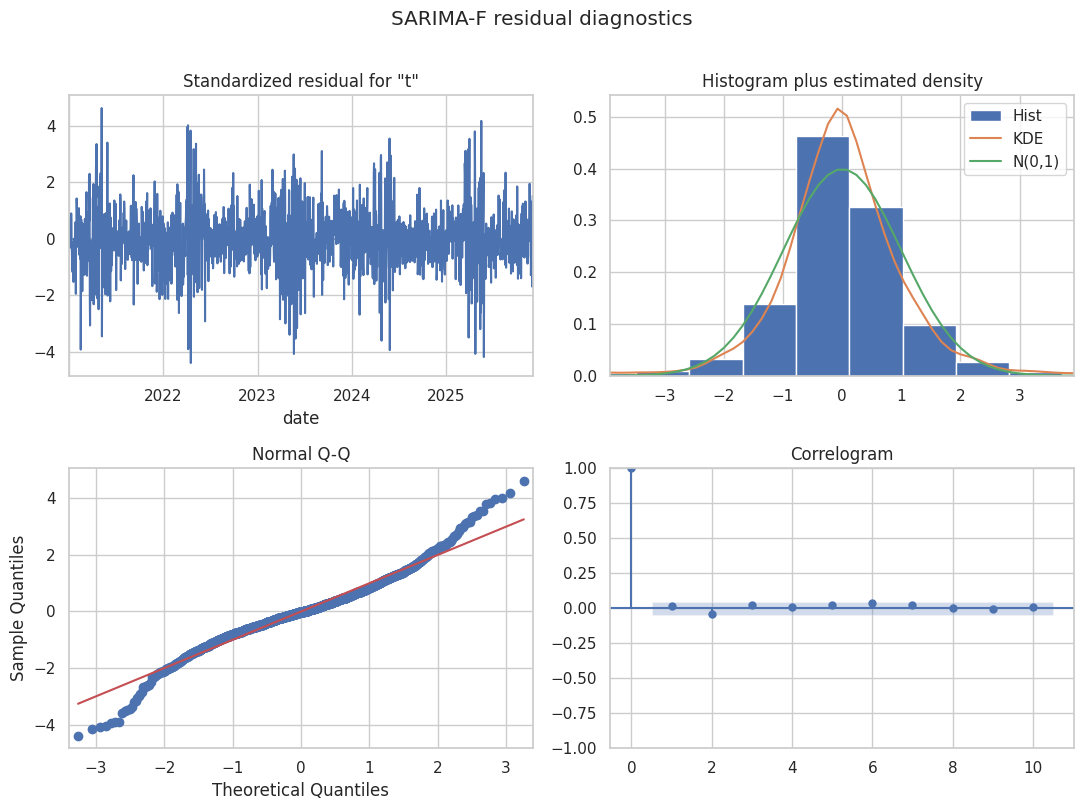

,lb_stat,lb_pvalue,verdict (p>0.05 = white noise)
7,8.0491,0.0898,OK
14,20.2462,0.0421,autocorrelation left
30,46.0478,0.0126,autocorrelation left


Residual mean = -0.005 C | std = 1.05 C | skew = 0.05 | excess kurtosis = 2.45


In [18]:
fig = sarima.plot_diagnostics(figsize=(11, 8)); fig.suptitle("SARIMA-F residual diagnostics", y=1.01)
fig.tight_layout()
savefig("05_sarima_diagnostics.png"); plt.show()

p_, d_, q_ = BEST_ORDER
resid = sarima.resid.iloc[max(d_, 1):]
lb = acorr_ljungbox(resid, lags=[7, 14, 30], model_df=p_ + q_, return_df=True)
lb["verdict (p>0.05 = white noise)"] = np.where(lb["lb_pvalue"] > 0.05, "OK", "autocorrelation left")
display(lb.round(4))
print(f"Residual mean = {resid.mean():.3f} C | std = {resid.std():.2f} C | skew = {stats.skew(resid):.2f} | excess kurtosis = {stats.kurtosis(resid):.2f}")

**Our result:** residual mean ≈ 0.00 °C and std ≈ 1.05 °C; Ljung-Box passes at lag 7 (p ≈ 0.09) but shows **a little autocorrelation left at lags 14 and 30 (p ≈ 0.04 and 0.01)**, and the residuals are **heavy-tailed** (excess kurtosis ≈ 2.5, Q-Q plot bends at both ends). So the model captures the main structure well but not everything: multi-day weather systems and occasional heat/cold spikes are beyond a linear model with 3 ARMA terms. That is acceptable for a baseline, but it means the **confidence intervals should be read with care**. The residual spread also changes with the season (rolling std from ≈ 0.5 to ≈ 2 °C), i.e. mild **heteroscedasticity**, which ARIMA assumes away.

**General guide:** the residual mean should be about 0. If Ljung-Box shows leftover autocorrelation, the model is missing short-range structure (e.g. multi-day weather systems that a linear ARIMA with few terms cannot fully capture), and the forecasts are still usable but the confidence intervals may be slightly too narrow. Heavy tails in the Q-Q plot mean occasional large errors (e.g. sudden heat waves or cold snaps).

##Forecasting with confidence intervals (30-day horizon)
We forecast all 30 test days **without ever seeing them** (a true multi-step forecast made at the end of the training data), together with a 95 % confidence interval, and compare with the baselines.

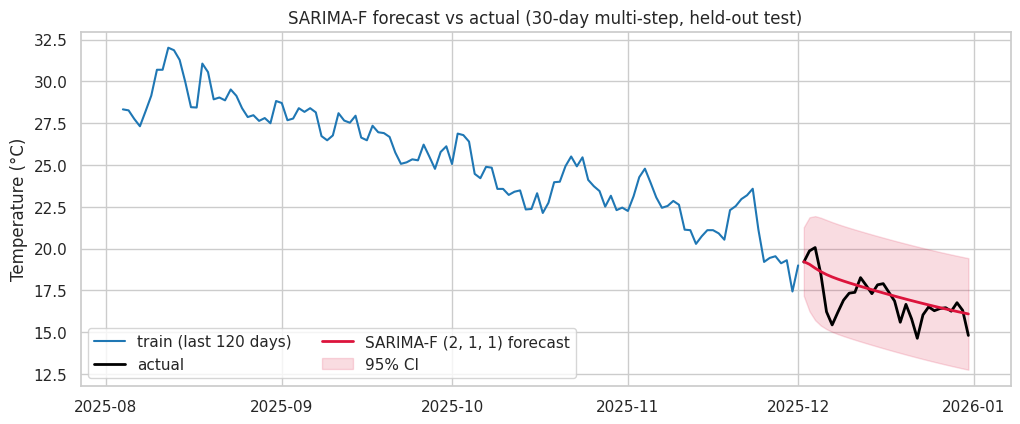

Share of actual test days inside the 95% interval: 100%
Interval half-width: h=1 -> +/-2.1 C | h=7 -> +/-3.3 C | h=30 -> +/-3.3 C


In [19]:
pred_mean, ci = forecast_sarimax(sarima, test.index, K_BEST)
arima_pred, arima_ci = forecast_sarimax(arima, test.index, 0)
snaive = pd.Series(seasonal_naive_fc(train, test.index), index=test.index)
persist = pd.Series(persistence_fc(train, test.index), index=test.index)

fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(train.index[-120:], train.iloc[-120:], label="train (last 120 days)", color="tab:blue")
ax.plot(test.index, test, label="actual", color="black", lw=2)
ax.plot(test.index, pred_mean, label=f"SARIMA-F {BEST_ORDER} forecast", color="crimson", lw=2)
ax.fill_between(test.index, ci.iloc[:, 0], ci.iloc[:, 1], color="crimson", alpha=0.15, label="95% CI")
ax.set_title("SARIMA-F forecast vs actual (30-day multi-step, held-out test)"); ax.set_ylabel("Temperature (°C)"); ax.legend(loc="lower left", ncol=2)
savefig("06_sarima_forecast.png"); plt.show()
inside = ((test.values >= ci.iloc[:, 0].values) & (test.values <= ci.iloc[:, 1].values)).mean()
print(f"Share of actual test days inside the 95% interval: {inside:.0%}")
print(f"Interval half-width: h=1 -> +/-{(ci.iloc[0,1]-ci.iloc[0,0])/2:.1f} C | h=7 -> +/-{(ci.iloc[6,1]-ci.iloc[6,0])/2:.1f} C | h=30 -> +/-{(ci.iloc[-1,1]-ci.iloc[-1,0])/2:.1f} C")

**Reading the interval (our run).** The 95 % interval widens from about **±2.1 °C at day 1 to ±3.3 °C by day 7 and then stays at about ±3.3 °C**: once the forecast has reverted to the seasonal average, the uncertainty is simply the normal day-to-day spread around that average. All 30 test days fall inside the interval, but **one window cannot validate an interval**, so we measure the real coverage over all 8 walk-forward windows in Section 5.2.

# 5. Evaluation

##Metrics on the held-out test set


All models forecast the same 30 days, **multi-step**: they only know the data up to the end of the training set.

In [20]:
test_metrics = pd.DataFrame({
    "Persistence (tomorrow = today)": metrics(test, persist),
    "Seasonal naive (same day last year)": metrics(test, snaive),
    f"ARIMA {ARIMA_ORDER} (non-seasonal)": metrics(test, arima_pred),
    f"SARIMA-F {BEST_ORDER} + {K_BEST} harmonics": metrics(test, pred_mean),
}).T
display(test_metrics.round(2))

,MAE,RMSE,MAPE (%),sMAPE (%)
Persistence (tomorrow = today),2.17,2.40,13.31,12.29
Seasonal naive (same day last year),1.40,1.74,8.29,8.70
"ARIMA (1, 0, 0) (non-seasonal)",1.83,2.05,11.20,10.46
"SARIMA-F (2, 1, 1) + 1 harmonics",0.73,1.05,4.50,4.33


## Time-aware validation: walk-forward (rolling origin)
One split gives one noisy number (30 days of a single season). Walk-forward validation refits the model at **8 different origins** spread over the last 8 months, forecasts the next 30 days each time, and averages. It also tells us how accuracy **degrades with the forecast horizon**.

In [21]:
N_FOLDS = 8
t0 = time.time()
wf = {
    "Persistence":     walk_forward(y, persistence_fc, N_FOLDS),
    "Seasonal naive":  walk_forward(y, seasonal_naive_fc, N_FOLDS),
    "ARIMA":           walk_forward(y, sarimax_forecaster(ARIMA_ORDER, 0), N_FOLDS),
    "SARIMA-F":        walk_forward(y, sarimax_forecaster(BEST_ORDER, K_BEST), N_FOLDS),
}
print(f"walk-forward done in {time.time()-t0:.0f}s")
folds_start = [y.index[te[0]].date() for _, te in TimeSeriesSplit(n_splits=N_FOLDS, test_size=H).split(y)]
wf_table = pd.DataFrame({k: {"mean MAE": v["mae"].mean(), "std MAE": v["mae"].std(), "mean RMSE": v["rmse"].mean()} for k, v in wf.items()}).T
display(wf_table.round(2))
display(pd.DataFrame({k: v["mae"] for k, v in wf.items()}, index=[str(d) for d in folds_start]).round(2).rename_axis("fold starts"))

# ---- empirical coverage of the 95% interval over the same folds
cov, width = [], []
for tr, te in TimeSeriesSplit(n_splits=N_FOLDS, test_size=H).split(y):
    ytr, yte = y.iloc[tr], y.iloc[te]
    m_, ci_ = forecast_sarimax(fit_sarimax(ytr, BEST_ORDER, K_BEST), yte.index, K_BEST)
    cov.append(((yte.values >= ci_.iloc[:, 0].values) & (yte.values <= ci_.iloc[:, 1].values)).mean()); width.append((ci_.iloc[:, 1] - ci_.iloc[:, 0]).values)
width = np.vstack(width).mean(axis=0)
print(f"\nEmpirical coverage of the nominal 95% interval over {N_FOLDS} folds: {np.mean(cov):.0%}  (per fold: {[f'{c:.0%}' for c in cov]})")
print(f"Mean interval width: h=1 -> {width[0]:.1f} C | h=7 -> {width[6]:.1f} C | h=30 -> {width[-1]:.1f} C")

walk-forward done in 6s


,mean MAE,std MAE,mean RMSE
Persistence,1.82,0.79,2.17
Seasonal naive,1.78,0.75,2.13
ARIMA,1.83,0.77,2.17
SARIMA-F,1.16,0.49,1.41


,Persistence,Seasonal naive,ARIMA,SARIMA-F
fold starts,,,,
2025-05-06,3.04,3.61,3.44,2.29
2025-06-05,1.23,2.20,1.65,1.15
2025-07-05,1.13,1.36,1.49,1.00
2025-08-04,1.08,1.30,1.26,0.96
2025-09-03,1.22,1.15,0.89,0.68
2025-10-03,3.06,1.57,2.64,0.98
2025-11-02,1.59,1.67,1.44,1.50
2025-12-02,2.17,1.40,1.83,0.73



Empirical coverage of the nominal 95% interval over 8 folds: 97%  (per fold: ['83%', '100%', '100%', '100%', '100%', '100%', '90%', '100%'])
Mean interval width: h=1 -> 4.2 C | h=7 -> 6.6 C | h=30 -> 6.7 C


**Reading the walk-forward results (our run)**
* **SARIMA-F wins clearly:** mean MAE ≈ **1.16 °C** vs ≈ 1.8 °C for persistence, seasonal-naive and the non-seasonal ARIMA, which are all about the same. SARIMA-F also has the **lowest error spread across folds** (std ≈ 0.5), so it is more *consistent*, not just better on average.
* **The three simple baselines are not separable:** the non-seasonal ARIMA is no better than "tomorrow = today" at 30 days, because without a seasonal term its forecast just drifts to the global average. This is exactly why the handout says plain ARIMA under-fits seasonal data.
* **Difficult folds** are spring/autumn (6 May and 3 Oct starts), when temperature changes fastest and weather swings are largest; summer folds are easy for every model.
* **Interval coverage:** over the 8 windows the nominal 95 % interval contained **97 %** of the actual days, so the intervals are **well calibrated, slightly conservative**. The only weak window is the one starting 6 May (**83 %**), the spring transition, when temperature rose faster than the seasonal curve expected. Also note that the mean interval is about **6.7 °C wide** at 30 days; it is honest, but wide compared with the 14.8 °C seasonal swing, which shows how limited a univariate forecast is beyond a week.

##Suggested plots
### Residuals over time, histogram and Q-Q plot (on the training data)

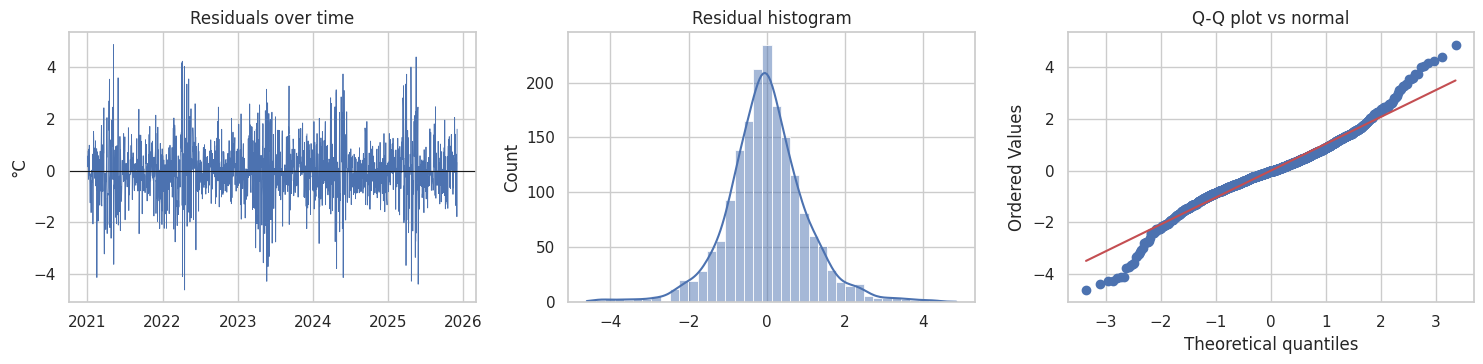

Rolling 30-day std of residuals ranges from 0.46 to 2.08 C -> noticeable heteroscedasticity (variance changes with the season).


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(resid.index, resid, lw=.6); axes[0].axhline(0, color="k", lw=.8)
axes[0].set_title("Residuals over time"); axes[0].set_ylabel("°C")
sns.histplot(resid, kde=True, ax=axes[1], bins=40); axes[1].set_title("Residual histogram")
stats.probplot(resid, dist="norm", plot=axes[2]); axes[2].set_title("Q-Q plot vs normal")
plt.tight_layout(); savefig("07_residual_plots.png"); plt.show()
rs = resid.rolling(30).std()
print(f"Rolling 30-day std of residuals ranges from {rs.min():.2f} to {rs.max():.2f} C -> "
      f"{'noticeable' if rs.max()/rs.min()>1.8 else 'mild'} heteroscedasticity (variance changes with the season).")

### Error by forecast horizon (walk-forward, h = 1 … 30 days)
Shows how fast accuracy degrades as we look further ahead. This is the honest answer to "how far can I trust the forecast?".

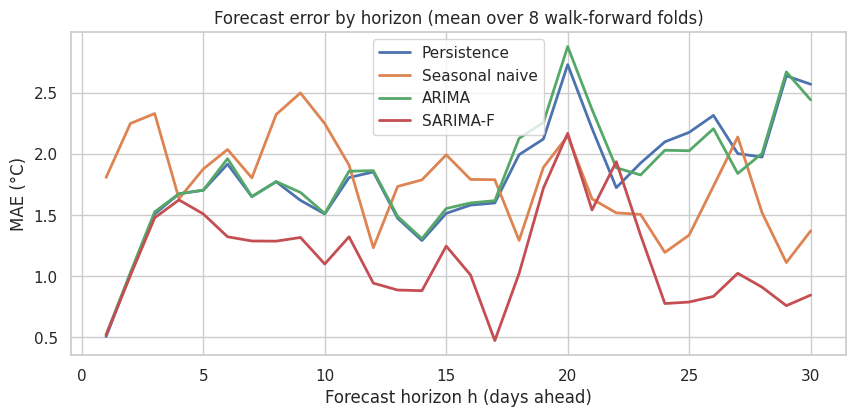

,Persistence,Seasonal naive,ARIMA,SARIMA-F
h=1,0.51,1.81,0.52,0.52
h=7,1.65,1.80,1.65,1.29
h=14,1.29,1.79,1.31,0.88
h=30,2.57,1.37,2.44,0.84


In [23]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for name, v in wf.items():
    ax.plot(range(1, H + 1), v["err"].mean(axis=0), label=name, lw=2)
ax.set_xlabel("Forecast horizon h (days ahead)"); ax.set_ylabel("MAE (°C)"); ax.set_title("Forecast error by horizon (mean over 8 walk-forward folds)")
ax.legend(); savefig("08_error_by_horizon.png"); plt.show()
hz = pd.DataFrame({k: v["err"].mean(axis=0)[[0, 6, 13, 29]] for k, v in wf.items()}, index=["h=1", "h=7", "h=14", "h=30"]).round(2)
display(hz)

**Reading the horizon plot (our run)**
* At **h = 1 day**, SARIMA-F, ARIMA and persistence are all about **0.5 °C**: tomorrow is mostly today.
* **Persistence and ARIMA get worse with horizon** (MAE ≈ 2.5 °C at 30 days) because the real temperature keeps moving with the season while they stay flat or revert to the global mean.
* **SARIMA-F's error does not keep growing with the horizon.** After roughly a week its forecast is essentially the **seasonal average for that date**, so beyond that point its MAE just **wobbles between about 0.5 and 2.2 °C** with no upward trend. The wobble is sampling noise, because each point is an average over only 8 windows. In other words, past ~1 week this model has **no day-specific skill**: it only knows the climate of the date. That is the real limit of any univariate model for weather.
* **Seasonal-naive is flat at ≈ 1.8 °C** at every horizon, because last year's same day differs from this year's by a year-to-year anomaly regardless of how far ahead we look.

### One-step-ahead evaluation (the easier setting)
Many LSTM tutorials (including the handout's) predict **one day ahead using the true previous days**. That is much easier than a 30-day forecast, so to compare fairly we also evaluate the statistical models in that setting: parameters stay fixed from training, but at each test day the model is updated with the **actual** observations up to the previous day.

In [24]:
y_all = y.copy()
def one_step(res_fit, K):
    full = res_fit.apply(y_all, exog=fourier(y_all.index, K), refit=False)           # same parameters, longer data
    return full.get_prediction(start=len(train), end=len(y_all) - 1, dynamic=False).predicted_mean.values

onestep = {
    "Persistence (tomorrow = today)": y_all.shift(1).loc[test.index].values,
    "Seasonal naive (same day last year)": y_all.shift(365).loc[test.index].values,
    "ARIMA": one_step(arima, 0),
    "SARIMA-F": one_step(sarima, K_BEST),
}
onestep_metrics = pd.DataFrame({k: metrics(test, v) for k, v in onestep.items()}).T
display(onestep_metrics.round(2))

,MAE,RMSE,MAPE (%),sMAPE (%)
Persistence (tomorrow = today),0.68,0.86,4.13,4.07
Seasonal naive (same day last year),1.40,1.74,8.29,8.70
ARIMA,0.68,0.85,4.13,4.08
SARIMA-F,0.57,0.74,3.42,3.38


# 6. Bonus: RNN and LSTM forecasting
A neural network sees fixed-length **windows**: the previous `n_steps = 30` days predict the next day.

We train three networks: a **Simple RNN** and an **LSTM** on the univariate series, plus an **LSTM with cyclical day-of-year features** (our feature engineering makes the season visible to the network).

*Note:* unlike `make_windows(test_scaled)`, we prepend the last 30 training days to the test data so that **all 30 test days** get a prediction.

In [25]:
try:
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Input, SimpleRNN, LSTM, Dense, Dropout
    from tensorflow.keras.callbacks import EarlyStopping
    tf.keras.utils.set_random_seed(SEED)
    HAVE_TF = True
    print("TensorFlow", tf.__version__)
except Exception as e:
    HAVE_TF = False
    print("TensorFlow not installed -> bonus section skipped. In Colab run:  !pip install tensorflow")

TensorFlow 2.21.0


In [26]:
N_STEPS = 30
if HAVE_TF:
    scaler = MinMaxScaler().fit(train.values.reshape(-1, 1))               # fit on TRAIN only
    s_all  = pd.Series(scaler.transform(y.values.reshape(-1, 1)).ravel(), index=y.index)
    cyc_all = np.column_stack([s_all.values, feat["doy_sin"].values, feat["doy_cos"].values])   # scaled temp + cyclical day-of-year
    uni_all = s_all.values.reshape(-1, 1)
    n_tr = len(train)

    def make_windows(arr, n_steps):                  # arr: (T, F); target = column 0 of the next row
        X, t = [], []
        for i in range(len(arr) - n_steps):
            X.append(arr[i:i + n_steps]); t.append(arr[i + n_steps, 0])
        return np.array(X), np.array(t)

    data = {}
    for name, arr in [("uni", uni_all), ("cyc", cyc_all)]:
        Xtr_, ytr_ = make_windows(arr[:n_tr], N_STEPS)                      # windows that live entirely in the training data
        Xall, yall = make_windows(arr, N_STEPS)
        Xte_, yte_ = Xall[n_tr - N_STEPS:], yall[n_tr - N_STEPS:]           # windows whose target is a test day
        data[name] = (Xtr_, ytr_, Xte_, yte_)
        print(name, "train windows:", Xtr_.shape, "| test windows:", Xte_.shape)
    assert len(data["uni"][3]) == H

uni train windows: (1766, 30, 1) | test windows: (30, 30, 1)
cyc train windows: (1766, 30, 3) | test windows: (30, 30, 3)


In [27]:
def build_rnn(n_feat):
    m = Sequential([Input(shape=(N_STEPS, n_feat)), SimpleRNN(32), Dense(1)]); m.compile(optimizer="adam", loss="mse"); return m
def build_lstm(n_feat):
    m = Sequential([Input(shape=(N_STEPS, n_feat)), LSTM(64, return_sequences=True), Dropout(0.2), LSTM(32), Dense(1)])
    m.compile(optimizer="adam", loss="mse"); return m

nets = {}; hist = {}
if HAVE_TF:
    for key, builder, dkey in [("Simple RNN", build_rnn, "uni"), ("LSTM", build_lstm, "uni"), ("LSTM + cyclical features", build_lstm, "cyc")]:
        tf.keras.utils.set_random_seed(SEED)
        Xtr_, ytr_, _, _ = data[dkey]
        m = builder(Xtr_.shape[2])
        es = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
        t0 = time.time()
        h = m.fit(Xtr_, ytr_, validation_split=0.1, epochs=100, batch_size=32, callbacks=[es], verbose=0)
        nets[key], hist[key] = m, h
        print(f"{key:28s} stopped after {len(h.history['loss'])} epochs | best val_loss = {min(h.history['val_loss']):.5f} | {time.time()-t0:.0f}s")

Simple RNN                   stopped after 100 epochs | best val_loss = 0.00108 | 29s
LSTM                         stopped after 33 epochs | best val_loss = 0.00166 | 37s
LSTM + cyclical features     stopped after 64 epochs | best val_loss = 0.00109 | 66s


### Training curves
Train and validation loss should both fall and then flatten. If validation loss rises while training loss keeps falling, the network is **overfitting** (early stopping restores the best weights).

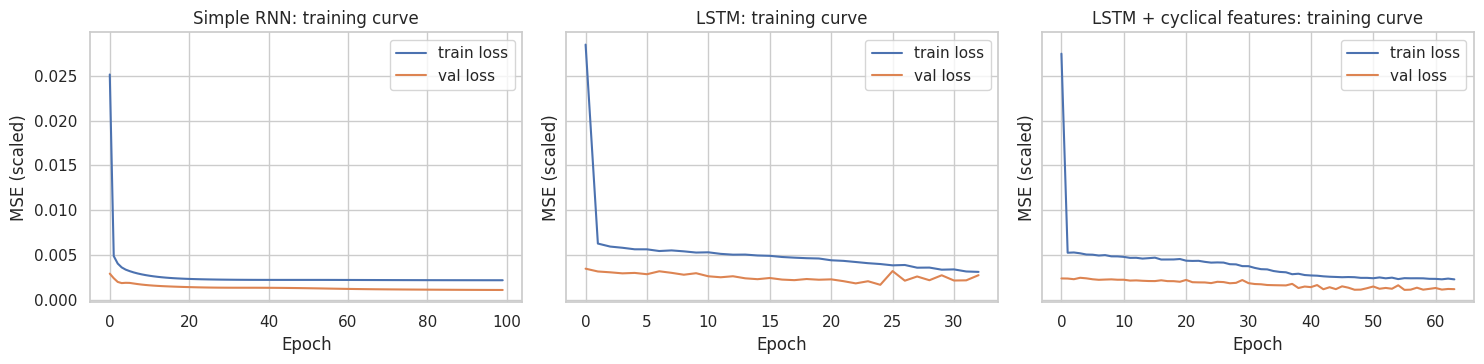

In [28]:
if HAVE_TF:
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
    for ax, (k, h) in zip(axes, hist.items()):
        ax.plot(h.history["loss"], label="train loss"); ax.plot(h.history["val_loss"], label="val loss")
        ax.set_title(f"{k}: training curve"); ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (scaled)"); ax.legend()
    plt.tight_layout(); savefig("09_training_curves.png"); plt.show()

### Inverse-transform and evaluate (two settings)
* **One-step-ahead:** predict each test day from the previous 30 **actual** days.
* **30-day recursive multi-step:** predict day 1, feed the prediction back in as input, predict day 2, and so on. This is the same task SARIMA-F faces, and errors accumulate .

In [29]:
inv = lambda a: scaler.inverse_transform(np.asarray(a).reshape(-1, 1)).ravel()
nn_one, nn_multi = {}, {}
if HAVE_TF:
    fut = feat.loc[test.index, ["doy_sin", "doy_cos"]].values                # calendar features are known in advance
    for key, m in nets.items():
        dkey = "cyc" if "cyclical" in key else "uni"
        Xtr_, ytr_, Xte_, yte_ = data[dkey]
        nn_one[key] = inv(m.predict(Xte_, verbose=0).ravel())                 # one-step-ahead
        arr = cyc_all if dkey == "cyc" else uni_all
        win = arr[n_tr - N_STEPS:n_tr].copy(); preds = []                     # recursive multi-step
        for h_ in range(H):
            p = m.predict(win[None], verbose=0)[0, 0]; preds.append(p)
            new = np.r_[p, fut[h_]] if dkey == "cyc" else np.array([p])
            win = np.vstack([win[1:], new])
        nn_multi[key] = inv(preds)
    print("One-step-ahead  :", {k: round(metrics(test, v)["MAE"], 2) for k, v in nn_one.items()})
    print("30-day recursive:", {k: round(metrics(test, v)["MAE"], 2) for k, v in nn_multi.items()})

One-step-ahead  : {'Simple RNN': 0.59, 'LSTM': 0.75, 'LSTM + cyclical features': 0.71}
30-day recursive: {'Simple RNN': 1.47, 'LSTM': 2.59, 'LSTM + cyclical features': 1.13}


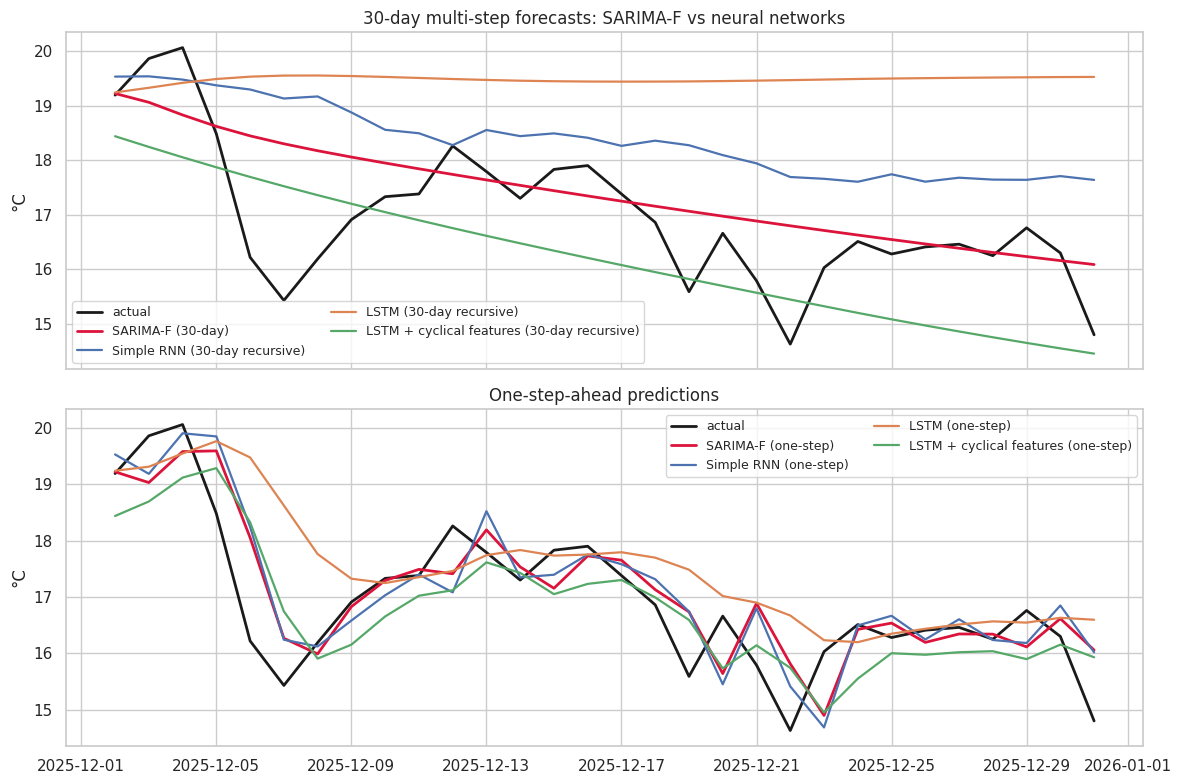

In [30]:
if HAVE_TF:
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    axes[0].plot(test.index, test, "k", lw=2, label="actual")
    axes[0].plot(test.index, pred_mean, color="crimson", lw=2, label="SARIMA-F (30-day)")
    for k, v in nn_multi.items(): axes[0].plot(test.index, v, lw=1.6, label=f"{k} (30-day recursive)")
    axes[0].set_title("30-day multi-step forecasts: SARIMA-F vs neural networks"); axes[0].set_ylabel("°C"); axes[0].legend(ncol=2, fontsize=9)
    axes[1].plot(test.index, test, "k", lw=2, label="actual")
    axes[1].plot(test.index, onestep["SARIMA-F"], color="crimson", lw=2, label="SARIMA-F (one-step)")
    for k, v in nn_one.items(): axes[1].plot(test.index, v, lw=1.6, label=f"{k} (one-step)")
    axes[1].set_title("One-step-ahead predictions"); axes[1].set_ylabel("°C"); axes[1].legend(ncol=2, fontsize=9)
    plt.tight_layout(); savefig("10_model_comparison.png"); plt.show()

**Reading the neural-network results (our run; the networks are random-initialised, so your decimals can differ slightly).**
* **One-step-ahead:** Simple RNN ≈ 0.59 °C, LSTM ≈ 0.75 °C, LSTM + cyclical features ≈ 0.71 °C, against **SARIMA-F 0.57 °C** and persistence 0.68 °C. No network beats SARIMA-F, and the plain LSTM is even *worse than "tomorrow = today"*. With only 30 test days a gap of 0.1 °C is within noise, so the honest summary is: **on one-step-ahead, SARIMA-F, the Simple RNN and persistence are practically tied.**
* **30-day recursive forecast** (the realistic task): **SARIMA-F 0.73 °C** vs LSTM + cyclical features ≈ 1.1 °C, Simple RNN ≈ 1.5 °C and LSTM ≈ 2.6 °C. The univariate networks **drift**: each prediction is fed back as input, so small errors accumulate and the forecast flattens out at a wrong level (top plot). The **cyclical day-of-year features help the most** (they roughly halve the plain LSTM's error) because they tell the network which season it is predicting.
* **Why the statistical model wins here:** the signal is a near-perfect smooth yearly wave plus short-memory noise. SARIMA-F encodes the wave with **two fitted numbers** (`sin1`, `cos1`) and the noise with three ARMA terms. A neural network has thousands of weights and only ~1,770 training windows (4 years), so it must *learn* a cycle that we can write down directly.
* **Training curves:** validation loss is *lower* than training loss because Keras takes the last 10 % of the windows for validation, which is a calmer winter stretch, and the LSTM applies dropout during training only. This is not a bug. The curves flatten, so the networks did converge; the early-stopping rule restored the best weights.

# 7. Model comparison and general tips

## Comparison table
Three views: **30-day test** (the realistic task), **walk-forward** mean MAE (8 folds, more reliable), and **one-step-ahead** (the easier task). Lower is better.

,MAE,RMSE,MAPE (%),Walk-forward MAE,One-step MAE,Notes
Model,,,,,,
Persistence,2.17,2.40,13.31,1.82,0.68,Naive baseline: flat line
Seasonal naive,1.40,1.74,8.29,1.78,1.40,Naive baseline: same day last year
"ARIMA (1, 0, 0)",1.83,2.05,11.20,1.83,0.68,Ignores the yearly cycle
"SARIMA-F (2, 1, 1)",0.73,1.05,4.50,1.16,0.57,Captures yearly cycle (1 Fourier harmonics)
Simple RNN,1.47,1.74,9.04,NaN,0.59,Bonus; walk-forward not run (retraining per fold)
LSTM,2.59,2.84,15.86,NaN,0.75,Bonus; walk-forward not run (retraining per fold)
LSTM + cyclical features,1.13,1.26,6.63,NaN,0.71,Bonus; walk-forward not run (retraining per fold)


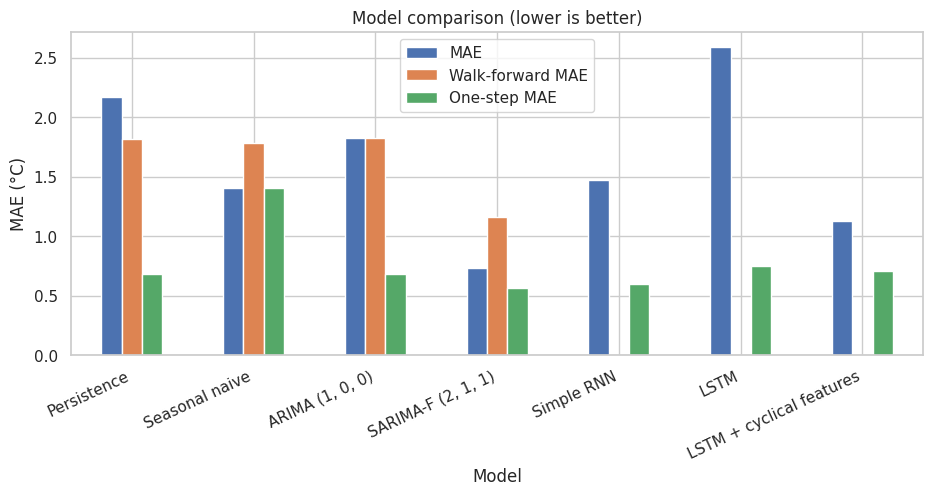

In [31]:
rows = []
def add(model, multi=None, wf_mae=None, one=None, note=""):
    r = {"Model": model, "MAE": np.nan, "RMSE": np.nan, "MAPE (%)": np.nan, "Walk-forward MAE": np.nan, "One-step MAE": np.nan, "Notes": note}
    if multi is not None: r.update({"MAE": multi["MAE"], "RMSE": multi["RMSE"], "MAPE (%)": multi["MAPE (%)"]})
    if wf_mae is not None: r["Walk-forward MAE"] = wf_mae
    if one is not None: r["One-step MAE"] = one["MAE"]
    rows.append(r)

add("Persistence", metrics(test, persist), wf["Persistence"]["mae"].mean(), metrics(test, onestep["Persistence (tomorrow = today)"]), "Naive baseline: flat line")
add("Seasonal naive", metrics(test, snaive), wf["Seasonal naive"]["mae"].mean(), metrics(test, onestep["Seasonal naive (same day last year)"]), "Naive baseline: same day last year")
add(f"ARIMA {ARIMA_ORDER}", metrics(test, arima_pred), wf["ARIMA"]["mae"].mean(), metrics(test, onestep["ARIMA"]), "Ignores the yearly cycle")
add(f"SARIMA-F {BEST_ORDER}", metrics(test, pred_mean), wf["SARIMA-F"]["mae"].mean(), metrics(test, onestep["SARIMA-F"]), f"Captures yearly cycle ({K_BEST} Fourier harmonics)")
if HAVE_TF:
    for k in nets:
        add(k, metrics(test, nn_multi[k]), None, metrics(test, nn_one[k]), "Bonus; walk-forward not run (retraining per fold)")
summary = pd.DataFrame(rows).set_index("Model")
summary.to_csv("model_comparison_summary.csv")
display(summary.round(2))

fig, ax = plt.subplots(figsize=(11, 4.2))
summary[["MAE", "Walk-forward MAE", "One-step MAE"]].plot(kind="bar", ax=ax)
ax.set_ylabel("MAE (°C)"); ax.set_title("Model comparison (lower is better)"); plt.xticks(rotation=25, ha="right")
savefig("11_model_comparison_bars.png"); plt.show()